# feature engineering

In [1]:
# standard libraries
import pandas as pd
import numpy as np
import os
from datetime import timedelta
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Scikit-learn imports
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# Set visualization style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.autolayout'] = True

# Resolve project base directory dynamically
PROJECT_ROOT = Path(os.getcwd()).resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'online+retail' / 'Online Retail.xlsx'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Data Path: {RAW_DATA_PATH}")


Project Root: C:\--------projects------\Customer_Segmentation--UCI-
Raw Data Path: C:\--------projects------\Customer_Segmentation--UCI-\data\raw\online+retail\Online Retail.xlsx


In [2]:
# Load raw dataset dynamically
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Raw data file not found at: {RAW_DATA_PATH}")

print("Loading raw Excel dataset (this may take a few seconds)...")
customer = pd.read_excel(RAW_DATA_PATH)
print(f"Dataset loaded successfully: {customer.shape[0]:,} rows, {customer.shape[1]} columns")
customer.head()


Loading raw Excel dataset (this may take a few seconds)...
Dataset loaded successfully: 541,909 rows, 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df=customer.copy()
print(f' shape of the data : {df.shape}')
print(f' columns in the data : {df.columns}')

 shape of the data : (541909, 8)
 columns in the data : Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


In [4]:
# Clean missing CustomerID and negative transactions
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
print(f"Rows after dropping null CustomerIDs: {df_clean.shape[0]:,}")

# Filter out cancellations and non-positive prices/quantities for RFM spend
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)].copy()
print(f"Rows after filtering positive Quantity & UnitPrice: {df_clean.shape[0]:,}")


Rows after dropping null CustomerIDs: 406,829
Rows after filtering positive Quantity & UnitPrice: 397,884


In [5]:
# Calculate Total Price per line item
df_clean['total_price'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Outlier handling: Rather than dropping transactions (which loses high-revenue wholesale orders),
# we record quantiles and clip extreme transaction anomalies at 99.9th percentile
qty_999 = df_clean['Quantity'].quantile(0.999)
price_999 = df_clean['UnitPrice'].quantile(0.999)

print(f"99.9th percentile Quantity: {qty_999:.1f}, UnitPrice: {price_999:.2f}")
df_clean = df_clean[(df_clean['Quantity'] <= qty_999) & (df_clean['UnitPrice'] <= price_999)].copy()

print(f"Cleaned dataset rows: {df_clean.shape[0]:,}")
print(f"Unique Customers: {df_clean['CustomerID'].nunique():,}")


99.9th percentile Quantity: 504.0, UnitPrice: 41.89
Cleaned dataset rows: 397,094
Unique Customers: 4,319


In [6]:
df_clean['InvoiceDate']=pd.to_datetime(df_clean['InvoiceDate'])
print(f' range of the invoicedate: {df_clean["InvoiceDate"].min()} to {df_clean["InvoiceDate"].max()}')


 range of the invoicedate: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [7]:
# Time and Regional Features
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.dayofweek
df_clean['DayName'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['IsWeekend'] = (df_clean['DayOfWeek'] >= 5).astype(int)
df_clean['Month'] = df_clean['InvoiceDate'].dt.month
df_clean['Quarter'] = df_clean['InvoiceDate'].dt.quarter
df_clean['IsBusinessHour'] = df_clean['Hour'].between(9, 17).astype(int)
df_clean['IsUK'] = (df_clean['Country'] == 'United Kingdom').astype(int)
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')

print("Engineered temporal & regional flags: IsWeekend, IsBusinessHour, IsUK")


Engineered temporal & regional flags: IsWeekend, IsBusinessHour, IsUK


In [8]:
# Cancellation Rate Calculation
df_with_id = df.dropna(subset=['CustomerID']).copy()
df_with_id['CustomerID'] = df_with_id['CustomerID'].astype(int)
df_with_id['IsCancelled'] = df_with_id['InvoiceNo'].astype(str).str.startswith('C').astype(int)

cancel_rate = df_with_id.groupby('CustomerID').agg(
    TotalInvoices=('InvoiceNo', 'count'),
    CancelledInvoices=('IsCancelled', 'sum')
).reset_index()

cancel_rate['CancelRate'] = (cancel_rate['CancelledInvoices'] / cancel_rate['TotalInvoices']).round(4)
print(f"Customers with cancellations: {(cancel_rate['CancelledInvoices'] > 0).sum():,} ({(cancel_rate['CancelledInvoices'] > 0).mean():.1%})")
print(f"Average Cancel Rate across customers: {cancel_rate['CancelRate'].mean():.4f}")
cancel_rate.head()


Customers with cancellations: 1,589 (36.3%)
Average Cancel Rate across customers: 0.0320


,CustomerID,TotalInvoices,CancelledInvoices,CancelRate
0,12346,2,1,0.5
1,12347,182,0,0.0
2,12348,31,0,0.0
3,12349,73,0,0.0
4,12350,17,0,0.0


In [9]:
#rfm
reference_date=df_clean['InvoiceDate'].max()+timedelta(days=1)
print(f' reference date : {reference_date.date()}')

rfm_core=df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate',lambda x: (reference_date-x.max()).days),
    Frequency=('InvoiceNo','nunique'),
    Monetary=('total_price','sum')

).reset_index()

print(f' rfm shape: {rfm_core.shape}')
print(rfm_core.describe().round(2))

 reference date : 2011-12-10
 rfm shape: (4319, 4)
       CustomerID  Recency  Frequency   Monetary
count     4319.00  4319.00    4319.00    4319.00
mean     15298.64    92.52       4.25    1883.82
std       1721.41    99.96       7.63    7665.93
min      12347.00     1.00       1.00       2.90
25%      13812.50    18.00       1.00     302.41
50%      15297.00    51.00       2.00     663.65
75%      16778.50   142.50       5.00    1626.55
max      18287.00   374.00     206.00  265207.26


In [10]:
# Customer-level aggregations
aggr = df_clean.groupby('CustomerID').agg(
    AvgOrderValue=('total_price', 'mean'),
    MaxOrderValue=('total_price', 'max'),
    MinOrderValue=('total_price', 'min'),
    OrderStdDev=('total_price', 'std'),
    TotalQuantity=('Quantity', 'sum'),
    ProductVariety=('StockCode', 'nunique'),
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max'),
    WeekendPurchaseRatio=('IsWeekend', 'mean'),
    AvgPurchaseHour=('Hour', 'mean'),
    BusinessHourRatio=('IsBusinessHour', 'mean'),
    IsUK=('IsUK', 'max')
).reset_index()

aggr['OrderStdDev'] = aggr['OrderStdDev'].fillna(0)
aggr['LifespanDays'] = (aggr['LastPurchase'] - aggr['FirstPurchase']).dt.days

print(f"Aggregated features shape: {aggr.shape}")
aggr[['CustomerID', 'AvgOrderValue', 'ProductVariety', 'LifespanDays', 'WeekendPurchaseRatio', 'AvgPurchaseHour']].head()


Aggregated features shape: (4319, 14)


,CustomerID,AvgOrderValue,ProductVariety,LifespanDays,WeekendPurchaseRatio,AvgPurchaseHour
0,12347,23.681319,103,365,0.000000,12.192308
1,12348,57.975484,22,282,0.096774,15.225806
2,12349,20.243750,72,0,0.000000,9.000000
3,12350,19.670588,17,0,0.000000,16.000000
4,12352,20.313902,58,260,0.000000,14.000000


In [11]:
#merging
rfm=rfm_core.merge(aggr,on='CustomerID',how='left')
rfm=rfm.merge(cancel_rate[['CustomerID','CancelRate']],on='CustomerID',how='left')
rfm['CancelRate']=rfm['CancelRate'].fillna(0)

print(f' merfed rfm table shape: {rfm.shape}')
print(f' columns : {list(rfm.columns)}')




 merfed rfm table shape: (4319, 18)
 columns : ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'MaxOrderValue', 'MinOrderValue', 'OrderStdDev', 'TotalQuantity', 'ProductVariety', 'FirstPurchase', 'LastPurchase', 'WeekendPurchaseRatio', 'AvgPurchaseHour', 'BusinessHourRatio', 'IsUK', 'LifespanDays', 'CancelRate']


In [12]:
# Derived Behavioral KPIs (Handling single-purchase customers cleanly)
# For customers with LifespanDays == 0 (one-time purchase), PurchaseRate is set to 0.0 or baseline
rfm['PurchaseRate'] = np.where(rfm['LifespanDays'] > 0, rfm['Frequency'] / rfm['LifespanDays'], 0.0)

# Days between purchases: Lifespan / (Frequency - 1) for repeat customers; 0.0 for single-purchase customers
rfm['AvgDaysBetweenPurchases'] = np.where(
    rfm['Frequency'] > 1,
    rfm['LifespanDays'] / np.maximum(rfm['Frequency'] - 1, 1),
    0.0
)

rfm['SpendPerProduct'] = rfm['Monetary'] / rfm['ProductVariety'].replace(0, 1)
rfm['QtyPerOrder'] = rfm['TotalQuantity'] / rfm['Frequency']
rfm['RevenuePerDay'] = np.where(rfm['LifespanDays'] > 0, rfm['Monetary'] / rfm['LifespanDays'], rfm['Monetary'])
rfm['UniqueProductPct'] = np.minimum(rfm['ProductVariety'] / rfm['TotalQuantity'].replace(0, 1), 1.0)

cv = rfm['OrderStdDev'] / rfm['AvgOrderValue'].replace(0, 1)
rfm['OrderValueConsistency'] = np.clip(1 - cv, 0, 1)

# CLV Score proxy: (Frequency * AvgOrderValue) / (Recency + 1)
rfm['CLV_score'] = (rfm['Frequency'] * rfm['AvgOrderValue']) / (rfm['Recency'] + 1)

derived_cols = ['PurchaseRate', 'AvgDaysBetweenPurchases', 'SpendPerProduct', 'QtyPerOrder', 'RevenuePerDay', 'UniqueProductPct', 'OrderValueConsistency', 'CLV_score']
print(rfm[derived_cols].describe().round(3).to_string())


       PurchaseRate  AvgDaysBetweenPurchases  SpendPerProduct  QtyPerOrder  RevenuePerDay  UniqueProductPct  OrderValueConsistency  CLV_score
count      4319.000                 4319.000         4319.000     4319.000       4319.000          4319.000               4319.000   4319.000
mean          0.037                   47.387           41.596      216.211        144.163             0.125                  0.334     22.560
std           0.526                   63.199          140.704      231.754        361.261             0.123                  0.272    288.641
min           0.000                    0.000            1.450        1.000          0.111             0.001                  0.000      0.006
25%           0.000                    0.000           13.857       93.000          5.944             0.056                  0.058      0.196
50%           0.015                   28.000           19.626      161.000         16.629             0.088                  0.316      0.798
75%   

In [13]:
# RFM Scoring (1 to 5) & Segment Labeling
n_bins = 5
rfm['R_score'] = pd.qcut(rfm['Recency'], q=n_bins, labels=list(range(n_bins, 0, -1))).astype(int)
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=n_bins, labels=list(range(1, n_bins + 1))).astype(int)
rfm['M_score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=n_bins, labels=list(range(1, n_bins + 1))).astype(int)

rfm['RFM_segment'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)
rfm['RFM_total'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']

def label_rfm_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r >= 3 and f >= 1 and m >= 3:
        return 'Potential Loyalist'
    elif r <= 2 and f >= 3 and m >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Lost / Hibernating'
    elif m >= 4: 
        return 'Big Spenders'
    else:
        return 'Needs Attention'

rfm['RFM_label'] = rfm.apply(label_rfm_segment, axis=1)

print("Segment distribution:")
print(rfm['RFM_label'].value_counts())


Segment distribution:
RFM_label
Loyal Customers       995
Champions             959
Lost / Hibernating    827
Needs Attention       593
At Risk               450
New Customers         318
Potential Loyalist    103
Big Spenders           74
Name: count, dtype: int64


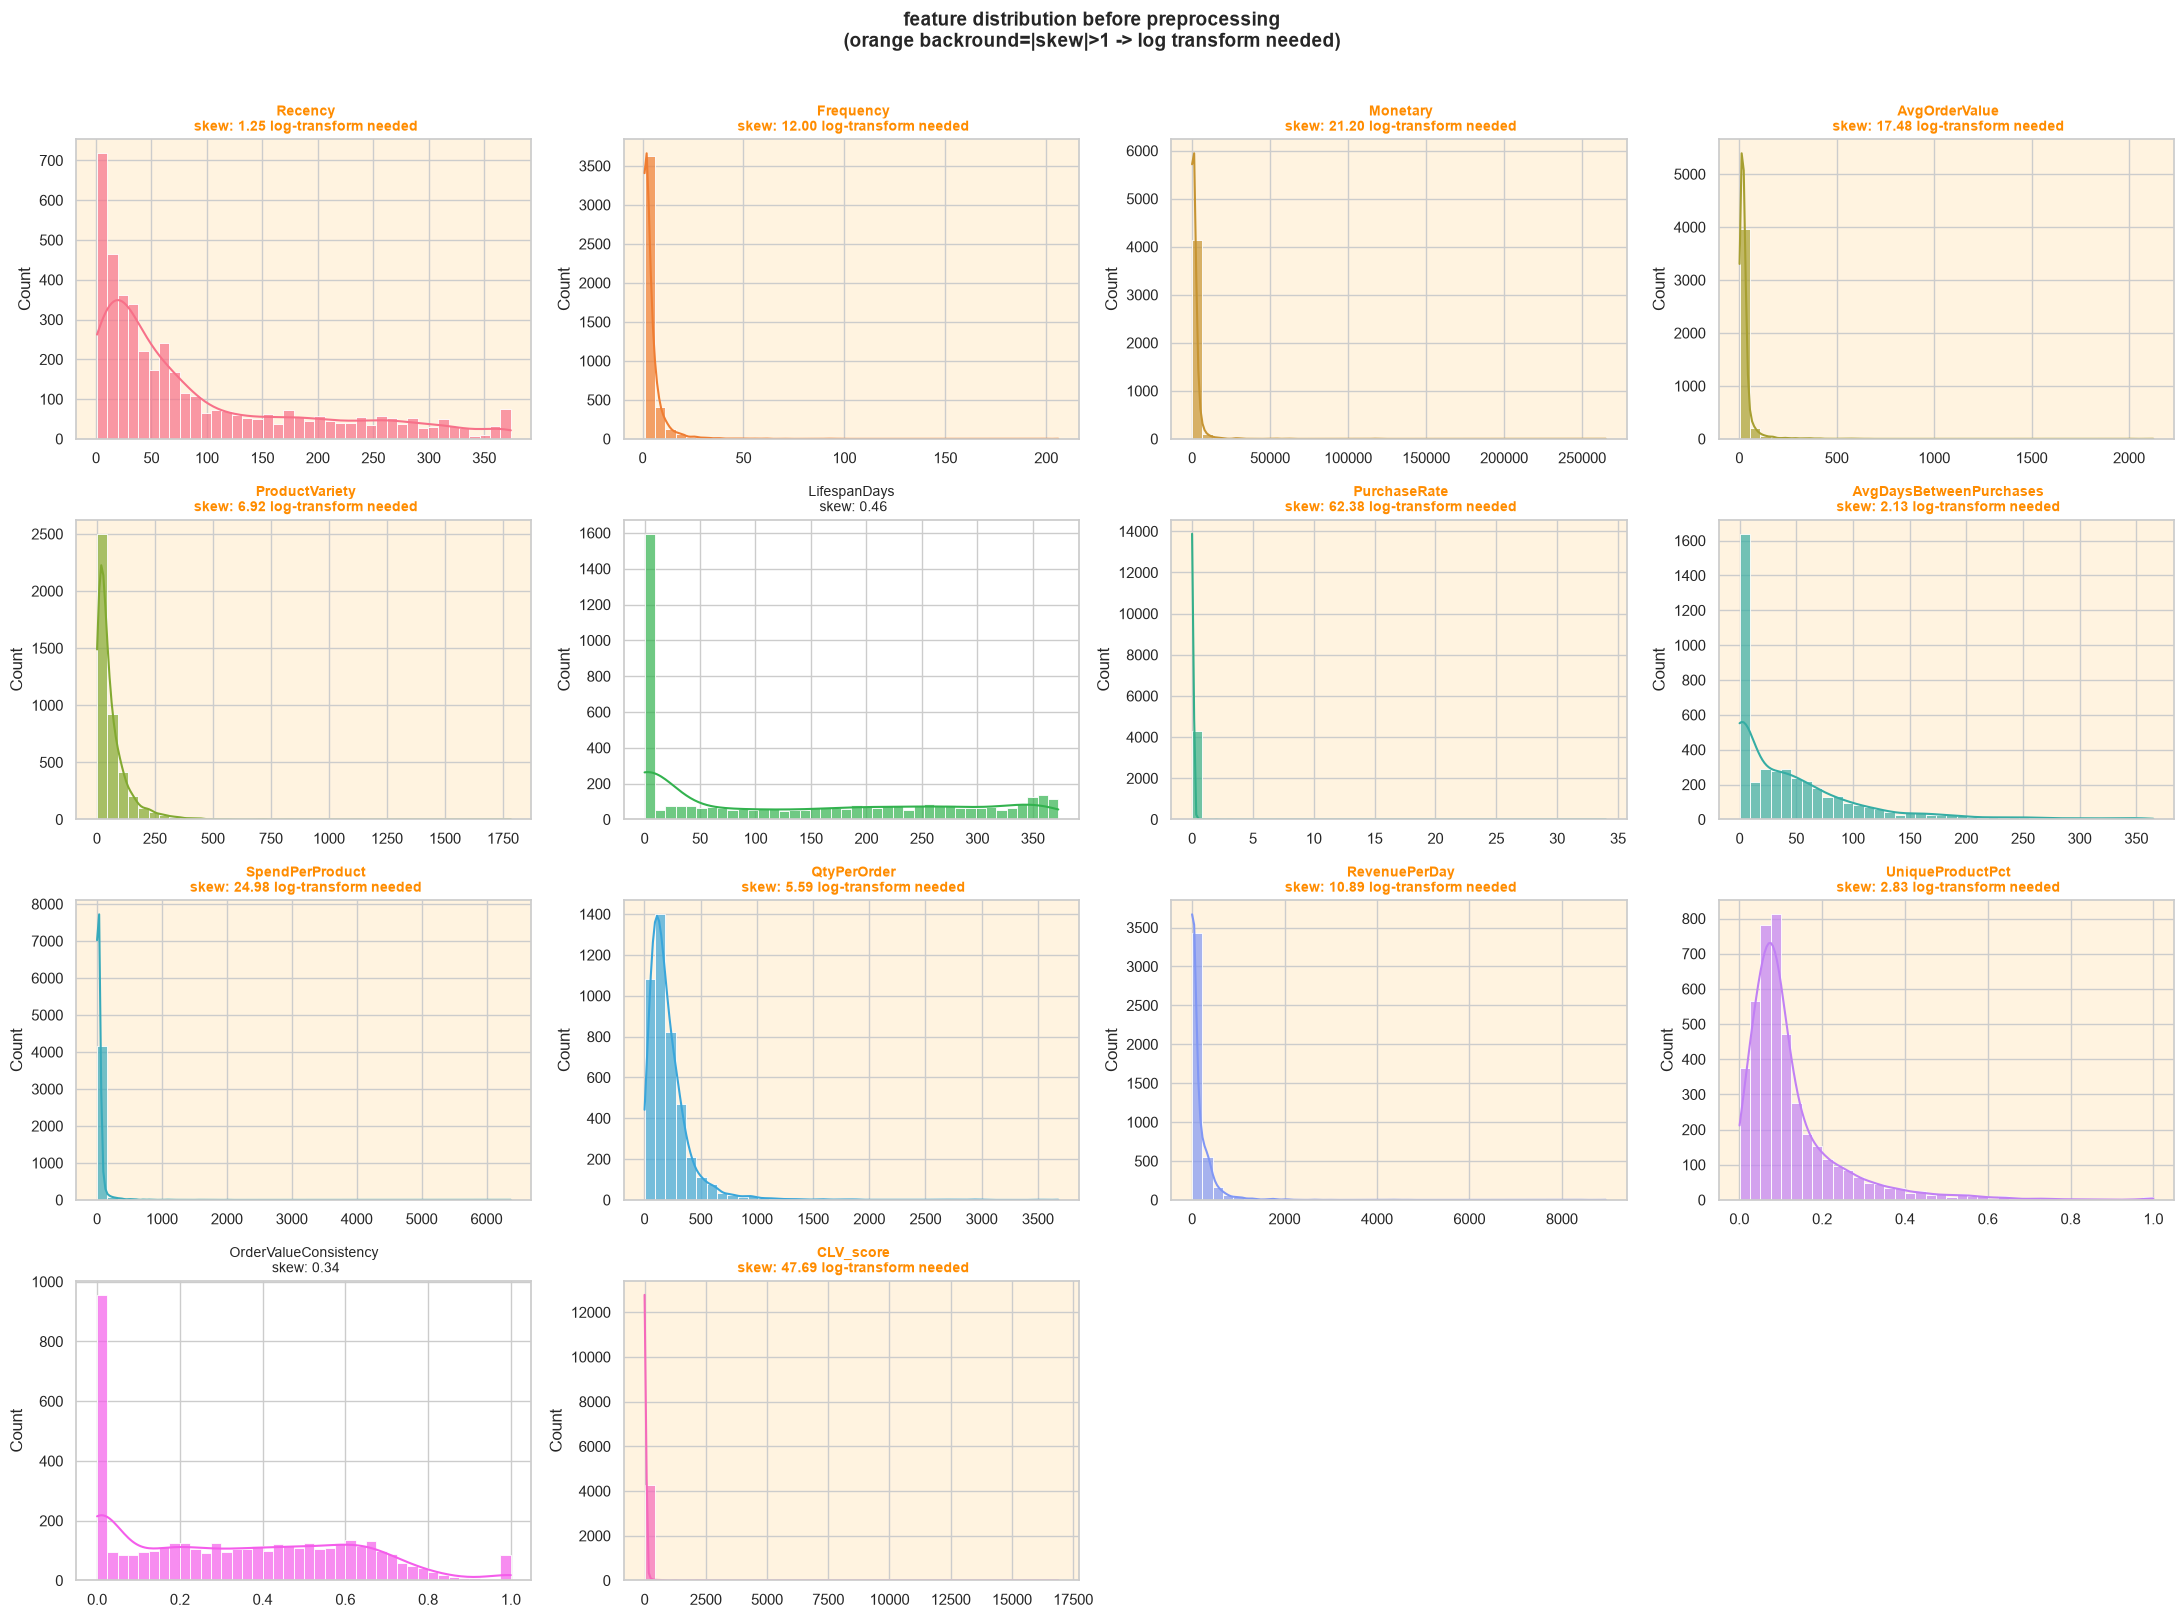

                Feature  Skewness  NeedsLogTransform
           PurchaseRate 62.376329               True
              CLV_score 47.692572               True
        SpendPerProduct 24.975570               True
               Monetary 21.195479               True
          AvgOrderValue 17.483029               True
              Frequency 12.002060               True
          RevenuePerDay 10.887011               True
         ProductVariety  6.917942               True
            QtyPerOrder  5.587138               True
       UniqueProductPct  2.833047               True
AvgDaysBetweenPurchases  2.131355               True
                Recency  1.245202               True
           LifespanDays  0.458021              False
  OrderValueConsistency  0.344739              False


In [14]:
model_features=[
        'Recency', 'Frequency', 'Monetary',
        'AvgOrderValue', 'ProductVariety', 'LifespanDays',
        'PurchaseRate', 'AvgDaysBetweenPurchases',
        'SpendPerProduct', 'QtyPerOrder',
        'RevenuePerDay', 'UniqueProductPct',
        'OrderValueConsistency', 'CLV_score'
    ]

n_features=len(model_features)

n_cols=4
n_rows=int(np.ceil(n_features/n_cols))

fig,axes=plt.subplots(n_rows,n_cols,figsize=(22,n_rows*4))
axes=axes.flatten()
colors=sns.color_palette('husl',n_features)

for i ,(feat,col) in enumerate(zip(model_features,colors)):
    ax=axes[i]
    data=rfm[feat].dropna()
    skew=data.skew()

    sns.histplot(data,bins=40,kde=True,color=col,ax=ax,alpha=0.7)
    ax.set_title(f'{feat}\n skew: {skew:.2f}',fontsize=10)
    ax.set_xlabel('')

    if abs(skew)>1:
        ax.set_facecolor('#fff3e0')
        ax.set_title(f' {feat}\n skew: {skew:.2f} log-transform needed',
                     fontsize=10,color='darkorange',fontweight='bold')
        
for j in range(i+1,len(axes)):
    axes[j].axis('off')

plt.suptitle('feature distribution before preprocessing\n'
             '(orange backround=|skew|>1 -> log transform needed)',fontsize=14,fontweight='bold',y=1.01)
plt.tight_layout()
plt.show()

skew_df=rfm[model_features].skew().sort_values(ascending=False).reset_index()
skew_df.columns=['Feature','Skewness']
skew_df['NeedsLogTransform']=skew_df['Skewness'].abs()>1

print(skew_df.to_string(index=False))


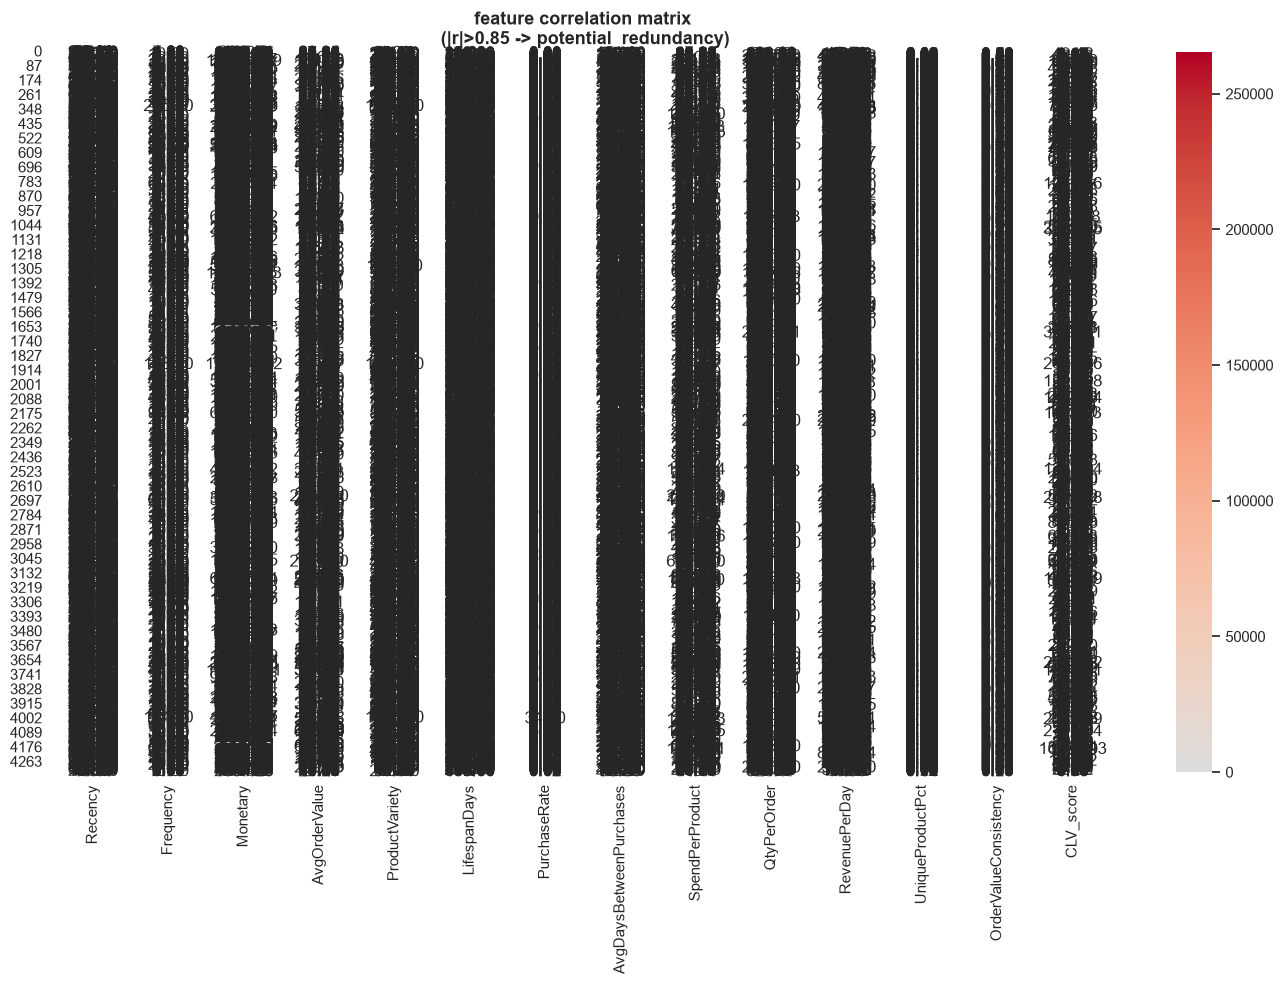


 high correlation pairs (|r| >0.85):
              Feature A               Feature B  Correlation
                Recency               Frequency        7.000
                Recency                Monetary     4310.000
                Recency           AvgOrderValue       23.681
                Recency          ProductVariety      103.000
                Recency            LifespanDays      365.000
                Recency AvgDaysBetweenPurchases       60.833
                Recency         SpendPerProduct       41.845
                Recency             QtyPerOrder      351.143
                Recency           RevenuePerDay       11.808
                Recency               CLV_score       55.256
              Frequency                Monetary     1797.240
              Frequency           AvgOrderValue       57.975
              Frequency          ProductVariety       22.000
              Frequency            LifespanDays      282.000
              Frequency AvgDaysBetweenPurchases

In [15]:
corr_matrix=rfm[model_features].copy()

fig,ax=plt.subplots(figsize=(14,10))
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))
sns.heatmap(corr_matrix,mask=mask,annot=True,fmt='.2f',cmap='coolwarm',center=0,linewidth=0.5,ax=ax)

ax.set_title('feature correlation matrix\n (|r|>0.85 -> potential  redundancy)',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.show()

print('\n high correlation pairs (|r| >0.85):')

high_corr=[]
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r=corr_matrix.iloc[i,j]
        if abs(r) >0.85:
            high_corr.append({
                'Feature A': corr_matrix.columns[i],
                'Feature B': corr_matrix.columns[j],
                'Correlation': round(r,3)
            })

if high_corr:
    print(pd.DataFrame(high_corr).to_string(index=False))
    print('\n -> consider dropping one  from each highly correlated pair')
else: 
    print(' no highly correlated pairs found')

In [16]:
# Custom Transformer: PercentileClipper
class PercentileClipper(BaseEstimator, TransformerMixin):
    """Clips features between specified percentiles to limit extreme outliers."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        
    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        self.lower_bounds_ = np.percentile(X_arr, self.lower * 100, axis=0)
        self.upper_bounds_ = np.percentile(X_arr, self.upper * 100, axis=0)
        return self
    
    def transform(self, X):
        X_arr = np.asarray(X)
        clipped = np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)
        if isinstance(X, pd.DataFrame):
            return pd.DataFrame(clipped, columns=X.columns, index=X.index)
        return clipped

    def get_feature_names_out(self, input_features=None):
        return input_features

print("PercentileClipper defined successfully.")


PercentileClipper defined successfully.


In [17]:
x=rfm[model_features].copy()

print(f' input shape: {x.shape}')
print(f' features : {list(x.columns)}')
print(f' nan count : {x.isnull().sum().sum()}')


preprocessor=Pipeline(
    steps=[
        ('log_transform',FunctionTransformer(np.log1p,validate=True)),
        ('outlier_clip',PercentileClipper(lower=0.01,upper=0.99)),
        ('scaler',StandardScaler()),

    ]
)

print('preprocessor pipeline defined')

x_processed=preprocessor.fit_transform(x)
x_processed_df=pd.DataFrame(x_processed,columns=model_features)

print(f'\n pipeline fitted and transformed')
print(f' output shape: {x_processed.shape}')
print(f' \n post-preprocessing statistics ')
print(x_processed_df.describe().round(3).to_string())


 input shape: (4319, 14)
 features : ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'ProductVariety', 'LifespanDays', 'PurchaseRate', 'AvgDaysBetweenPurchases', 'SpendPerProduct', 'QtyPerOrder', 'RevenuePerDay', 'UniqueProductPct', 'OrderValueConsistency', 'CLV_score']
 nan count : 0
preprocessor pipeline defined

 pipeline fitted and transformed
 output shape: (4319, 14)
 
 post-preprocessing statistics 
        Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  LifespanDays  PurchaseRate  AvgDaysBetweenPurchases  SpendPerProduct  QtyPerOrder  RevenuePerDay  UniqueProductPct  OrderValueConsistency  CLV_score
count  4319.000   4319.000  4319.000       4319.000        4319.000      4319.000      4319.000                 4319.000         4319.000     4319.000       4319.000          4319.000               4319.000   4319.000
mean     -0.000      0.000    -0.000         -0.000           0.000         0.000         0.000                   -0.000            0.000       -0.0

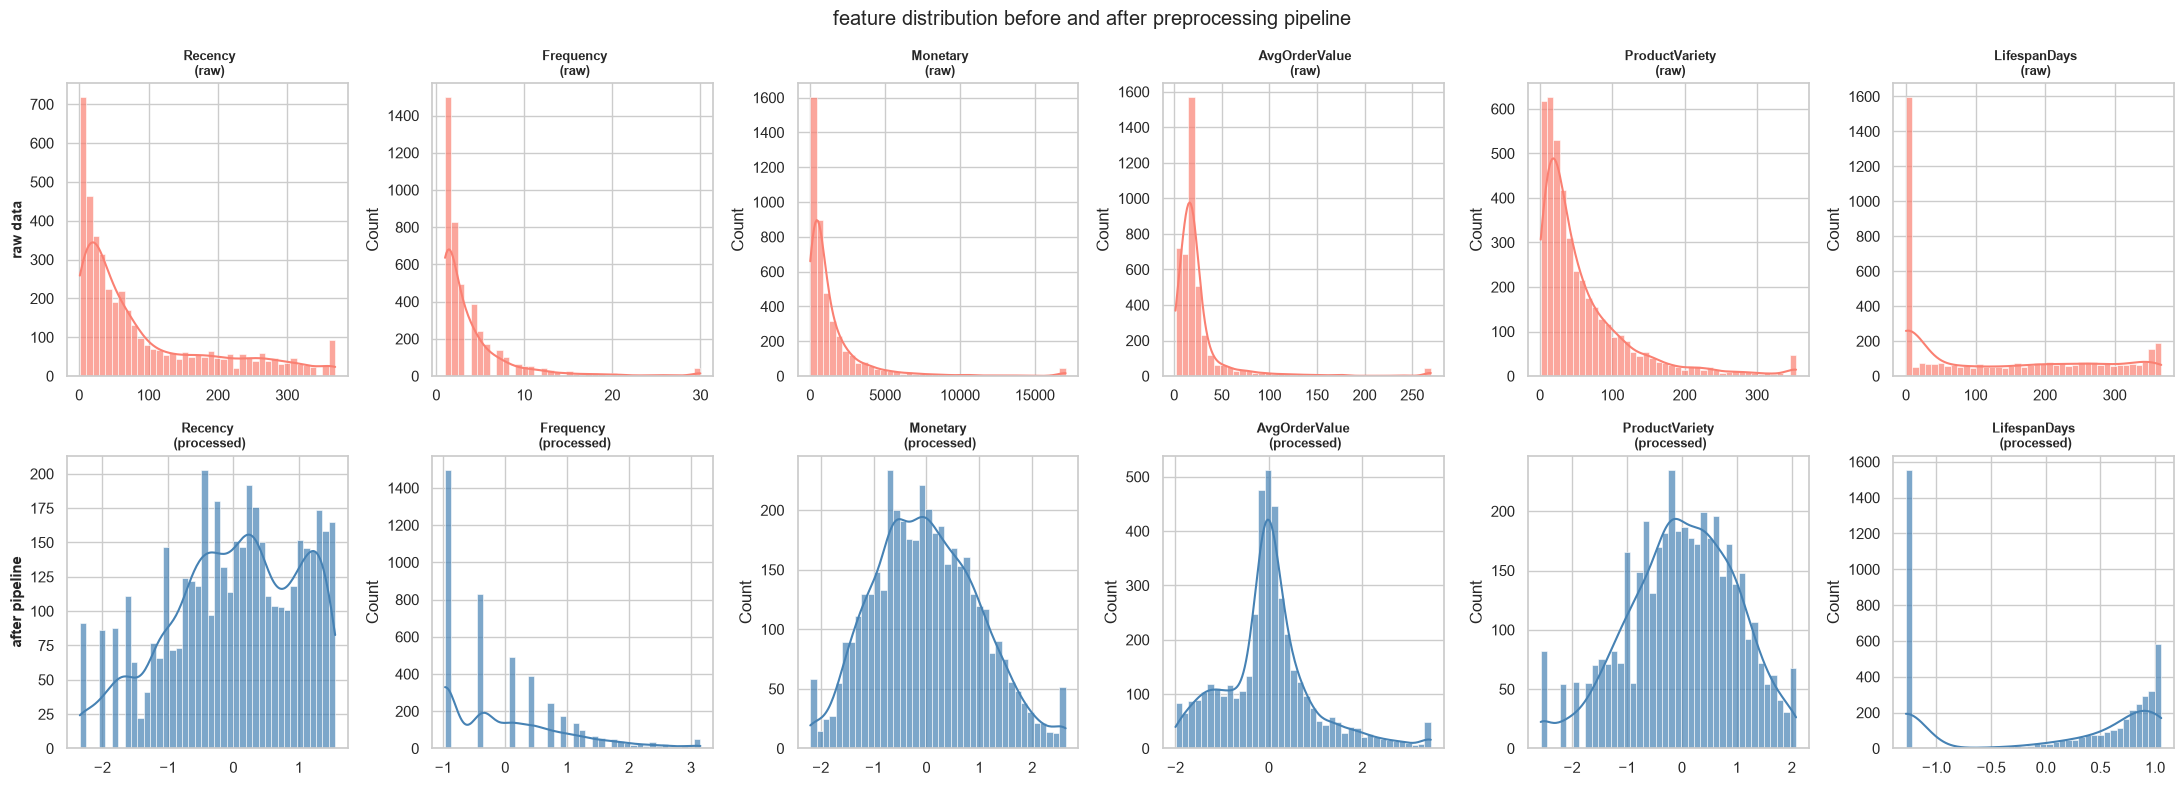

In [18]:
showcase_features=model_features[:6]
n=len(showcase_features)
fig,axes=plt.subplots(2,n,figsize=(22,8))

for i,feat in enumerate(showcase_features):
    sns.histplot(rfm[feat].clip(upper=rfm[feat].quantile(0.99)),bins=40,kde=True,ax=axes[0,i],color='salmon',alpha=0.7)
    axes[0,i].set_title(f' {feat}\n (raw)',fontsize=9,fontweight='bold')
    axes[0,i].set_xlabel('')

    sns.histplot(x_processed_df[feat],bins=40,kde=True,ax=axes[1,i],color='steelblue',alpha=0.7)
    axes[1,i].set_title(f'{feat}\n (processed)',fontsize=9,fontweight='bold')
    axes[1,i].set_xlabel('')

axes[0,0].set_ylabel('raw data',fontsize=10,fontweight='bold')
axes[1,0].set_ylabel('after pipeline',fontsize=11,fontweight='bold')

plt.suptitle('feature distribution before and after preprocessing pipeline')
plt.tight_layout()
plt.show()



In [19]:
# Export Cleaned Features & Preprocessor Artifacts
rfm_export = rfm[['CustomerID'] + model_features + [
    'R_score', 'F_score', 'M_score', 'RFM_segment', 'RFM_label',
    'CancelRate', 'WeekendPurchaseRatio', 'AvgPurchaseHour', 'IsUK'
]].copy()

rfm_csv_path = PROCESSED_DIR / 'rfm_features.csv'
rfm_export.to_csv(rfm_csv_path, index=False)
print(f"RFM features exported: {rfm_csv_path} (Shape: {rfm_export.shape})")

npy_path = PROCESSED_DIR / 'x_processed.npy'
np.save(npy_path, x_processed)
print(f"Processed feature matrix saved: {npy_path} (Shape: {x_processed.shape})")

features_name_path = PROCESSED_DIR / 'model_features.txt'
with open(features_name_path, 'w') as f:
    f.write('\n'.join(model_features))
print(f"Model feature names saved: {features_name_path}")

pipeline_path_joblib = MODELS_DIR / 'preprocessor.joblib'
pipeline_path_pkl = MODELS_DIR / 'preprocessor.pkl'
joblib.dump(preprocessor, pipeline_path_joblib)
joblib.dump(preprocessor, pipeline_path_pkl)
print(f"Preprocessing pipeline saved to:\n  - {pipeline_path_joblib}\n  - {pipeline_path_pkl}")


RFM features exported: C:\--------projects------\Customer_Segmentation--UCI-\data\processed\rfm_features.csv (Shape: (4319, 24))
Processed feature matrix saved: C:\--------projects------\Customer_Segmentation--UCI-\data\processed\x_processed.npy (Shape: (4319, 14))
Model feature names saved: C:\--------projects------\Customer_Segmentation--UCI-\data\processed\model_features.txt
Preprocessing pipeline saved to:
  - C:\--------projects------\Customer_Segmentation--UCI-\models\preprocessor.joblib
  - C:\--------projects------\Customer_Segmentation--UCI-\models\preprocessor.pkl


In [20]:
print('feature engineering summary report')
print(' customr segmentation -uci online retail')

print(f'raw transactions : {customer.shape[0]:>10,}')
print(f' after cleaning : {df_clean.shape[0]:>10,}')
print(f' unique customers: {rfm.shape[0]:>10,}')

print(f' \n features engineered')


feature_groups = {
    'RFM Core'       : ['Recency', 'Frequency', 'Monetary'],
    'Order Value'    : ['AvgOrderValue', 'MaxOrderValue', 'MinOrderValue', 'OrderStdDev'],
    'Behavioral'     : ['ProductVariety', 'TotalQuantity', 'QtyPerOrder', 'UniqueProductPct'],
    'Loyalty Depth'  : ['LifespanDays', 'PurchaseRate', 'AvgDaysBetweenPurchases'],
    'Value KPIs'     : ['SpendPerProduct', 'RevenuePerDay', 'CLV_score'],
    'Consistency'    : ['OrderValueConsistency', 'CancelRate'],
    'Time Behavior'  : ['WeekendPurchaseRatio', 'AvgPurchaseHour', 'BusinessHourRatio'],
    'RFM Scores'     : ['R_score', 'F_score', 'M_score', 'RFM_segment', 'RFM_label'],
}

for group,cols in feature_groups.items():
    print(f' {group:<18}: {len(cols)} features -{cols}')




feature engineering summary report
 customr segmentation -uci online retail
raw transactions :    541,909
 after cleaning :    397,094
 unique customers:      4,319
 
 features engineered
 RFM Core          : 3 features -['Recency', 'Frequency', 'Monetary']
 Order Value       : 4 features -['AvgOrderValue', 'MaxOrderValue', 'MinOrderValue', 'OrderStdDev']
 Behavioral        : 4 features -['ProductVariety', 'TotalQuantity', 'QtyPerOrder', 'UniqueProductPct']
 Loyalty Depth     : 3 features -['LifespanDays', 'PurchaseRate', 'AvgDaysBetweenPurchases']
 Value KPIs        : 3 features -['SpendPerProduct', 'RevenuePerDay', 'CLV_score']
 Consistency       : 2 features -['OrderValueConsistency', 'CancelRate']
 Time Behavior     : 3 features -['WeekendPurchaseRatio', 'AvgPurchaseHour', 'BusinessHourRatio']
 RFM Scores        : 5 features -['R_score', 'F_score', 'M_score', 'RFM_segment', 'RFM_label']


In [21]:
# Verify loaded artifacts
loaded_x = np.load(PROCESSED_DIR / 'x_processed.npy')
loaded_rfm = pd.read_csv(PROCESSED_DIR / 'rfm_features.csv')
loaded_preprocessor = joblib.load(MODELS_DIR / 'preprocessor.joblib')

print("Verification Check:")
print(f"  - Loaded X shape: {loaded_x.shape}")
print(f"  - Loaded RFM shape: {loaded_rfm.shape}")
print(f"  - Loaded Preprocessor steps: {[s[0] for s in loaded_preprocessor.steps]}")
print("All feature engineering artifacts are verified and self-contained!")


Verification Check:
  - Loaded X shape: (4319, 14)
  - Loaded RFM shape: (4319, 24)
  - Loaded Preprocessor steps: ['log_transform', 'outlier_clip', 'scaler']
All feature engineering artifacts are verified and self-contained!
